In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

Active Device: cpu
Cloning official PINN4SOH repository...


Cloning into 'PINN4SOH'...


Repository cloned successfully!
Loading and cleaning test battery: PINN4SOH/data/XJTU data/2C_battery-4.csv
Loaded 362 clean operational cycles.
[PINN4SOH] Loaded weights from: PINN4SOH/pretrained model/model_XJTU_0.pth

             BATTERY KNEE-POINT PROGNOSIS & LIFECYCLE REPORT           
 Evaluated Battery File        : 2C_battery-4.csv
 Total Cycle Life Recorded     : 362 cycles
 Current Fleet Operating Cycle : Cycle 80
 Predicted Knee-Point Cycle    : Cycle 58
 Model Predicted SOH at Knee   : 98.41 %
 Actual Laboratory SOH at Knee : 98.0 %
 Prediction Error at Knee      : 0.41 %
 Safe Cycles Remaining         : 0 cycles
🚨 STATUS: CRITICAL RISK! POST-KNEE-POINT REGIME
 ► Battery has passed its knee rollover! Immediate risk of mid-shift range collapse.
 ► De-rate motor torque immediately and restrict order bundles to < 20 kg.


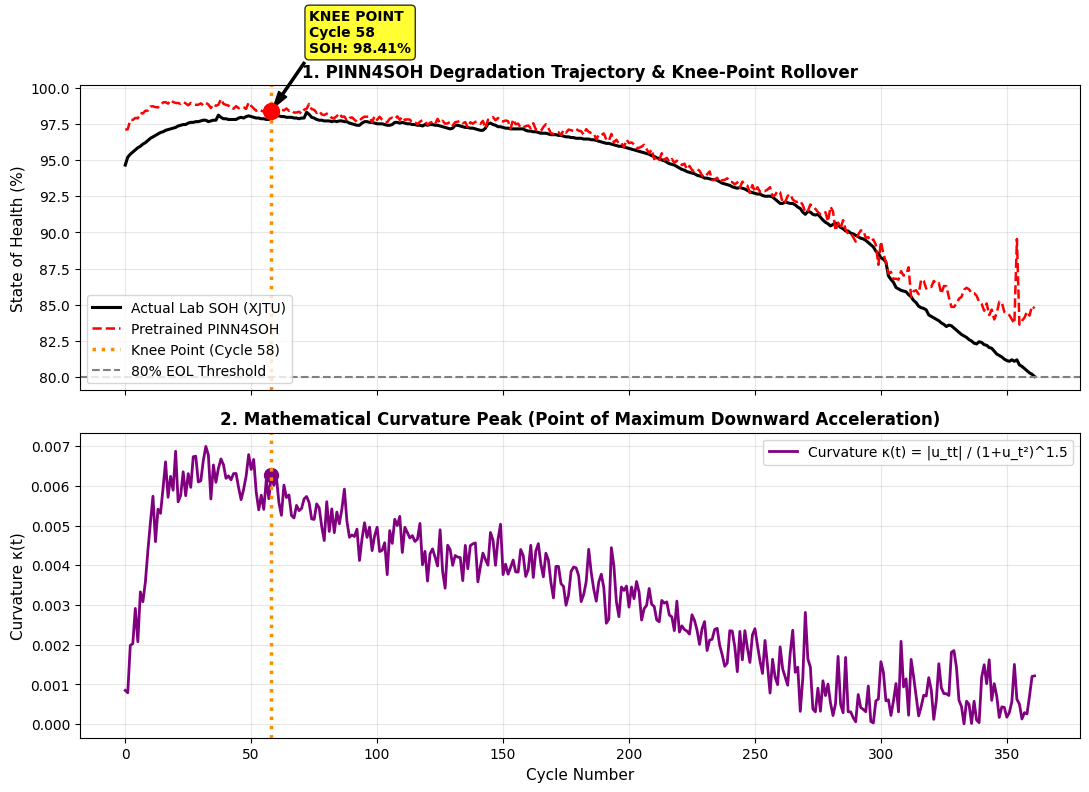

In [2]:
# ==============================================================================
# PINN4SOH: AUTOMATIC KNEE-POINT DETECTION ON XJTU BATTERY DATASET
# (100% Self-Contained Kaggle Cell)
# ==============================================================================

import os
import subprocess
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.autograd import grad
import matplotlib.pyplot as plt

# 1. Setup Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Active Device: {device}")

# 2. Ensure Official Repo Exists
REPO_DIR = "PINN4SOH"
if not os.path.exists(REPO_DIR):
    print("Cloning official PINN4SOH repository...")
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/wang-fujin/PINN4SOH.git", REPO_DIR], check=True)
    print("Repository cloned successfully!")

# ------------------------------------------------------------------------------
# 3. OFFICIAL MODEL ARCHITECTURE
# ------------------------------------------------------------------------------
class Sin(nn.Module):
    def forward(self, x):
        return torch.sin(x)

class MLP(nn.Module):
    def __init__(self, input_dim=17, output_dim=1, layers_num=4, hidden_dim=50, dropout=0.2):
        super(MLP, self).__init__()
        layers = []
        for i in range(layers_num):
            if i == 0:
                layers.append(nn.Linear(input_dim, hidden_dim))
                layers.append(Sin())
            elif i == layers_num - 1:
                layers.append(nn.Linear(hidden_dim, output_dim))
            else:
                layers.append(nn.Linear(hidden_dim, hidden_dim))
                layers.append(Sin())
                layers.append(nn.Dropout(p=dropout))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

class Predictor(nn.Module):
    def __init__(self, input_dim=32):
        super(Predictor, self).__init__()
        self.net = nn.Sequential(
            nn.Dropout(p=0.2),
            nn.Linear(input_dim, 32),
            Sin(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x)

class Solution_u(nn.Module):
    def __init__(self, in_dim=17):
        super(Solution_u, self).__init__()
        self.encoder = MLP(input_dim=in_dim, output_dim=32, layers_num=3, hidden_dim=60, dropout=0.2)
        self.predictor = Predictor(input_dim=32)

    def forward(self, x):
        return self.predictor(self.encoder(x))

class OfficialPINN4SOH(nn.Module):
    def __init__(self, in_features=17, f_in_dim=35):
        super(OfficialPINN4SOH, self).__init__()
        self.solution_u = Solution_u(in_dim=in_features).to(device)
        self.dynamical_F = MLP(input_dim=f_in_dim, output_dim=1, layers_num=3, hidden_dim=60, dropout=0.2).to(device)

    def load_official_pretrained(self, model_path):
        checkpoint = torch.load(model_path, map_location=device)
        self.solution_u.load_state_dict(checkpoint['solution_u'])
        self.dynamical_F.load_state_dict(checkpoint['dynamical_F'])
        print(f"[PINN4SOH] Loaded weights from: {model_path}")

# ------------------------------------------------------------------------------
# 4. LOAD & CLEAN XJTU TEST DATA (Prevents any NaN issues)
# ------------------------------------------------------------------------------
# You can test any cell: 2C_battery-1.csv, 2C_battery-2.csv, 2C_battery-4.csv, 3C_battery-4.csv
test_csv_path = os.path.join(REPO_DIR, "data", "XJTU data", "2C_battery-4.csv")
print(f"Loading and cleaning test battery: {test_csv_path}")

df_raw = pd.read_csv(test_csv_path)

# Remove any NaN or Inf values from kurtosis/skewness columns
df_clean = df_raw.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)

# Insert cycle index as 17th feature
df_clean.insert(df_clean.shape[1] - 1, 'cycle index', np.arange(df_clean.shape[0]))

# Extract features matrix (17 cols) and ground truth capacity (last col)
x_raw = df_clean.iloc[:, :-1].values
y_raw = df_clean.iloc[:, -1].values

nominal_capacity = 2.0  # 2.0 Ah nominal for XJTU 18650 cells
y_true_soh = (y_raw / nominal_capacity) * 100.0  # In percentage
total_cycles = len(y_true_soh)

print(f"Loaded {total_cycles} clean operational cycles.")

# ------------------------------------------------------------------------------
# 5. INITIALIZE MODEL & LOAD OFFICIAL PRETRAINED WEIGHTS
# ------------------------------------------------------------------------------
pinn_model = OfficialPINN4SOH().to(device)
weights_path = os.path.join(REPO_DIR, "pretrained model", "model_XJTU_0.pth")
pinn_model.load_official_pretrained(weights_path)
pinn_model.eval()

# ------------------------------------------------------------------------------
# 6. KNEE-POINT DETECTION VIA SECOND-ORDER CURVATURE (κ)
# ------------------------------------------------------------------------------
def evaluate_battery_knee_point(pinn, x_data, y_data):
    """
    Computes SOH trajectory and uses analytical autograd curvature to locate the knee point.
    """
    # Min-max normalization matching repository dataloader
    f_min = x_data.min(axis=0)
    f_max = x_data.max(axis=0)
    x_norm = 2.0 * (x_data - f_min) / (f_max - f_min + 1e-8) - 1.0

    # Tensor conversion with gradient tracking enabled on time coordinate
    xt_tensor = torch.tensor(x_norm, dtype=torch.float32, device=device)
    x_static = xt_tensor[:, 0:-1]
    t_coord = xt_tensor[:, -1:]
    t_coord.requires_grad_(True)

    # 1. Forward Pass: Predicted SOH trajectory
    u_pred = pinn.solution_u(torch.cat([x_static, t_coord], dim=1))

    # 2. First Derivative (du/dt: Degradation Velocity)
    u_t = grad(
        outputs=u_pred.sum(),
        inputs=t_coord,
        create_graph=True,
        retain_graph=True
    )[0]

    # 3. Second Derivative (d²u/dt²: Degradation Acceleration)
    u_tt = grad(
        outputs=u_t.sum(),
        inputs=t_coord,
        create_graph=False,
        retain_graph=False
    )[0]

    # Extract numpy vectors
    soh_pred = u_pred.detach().cpu().numpy().flatten() * 100.0
    vel = u_t.detach().cpu().numpy().flatten()
    acc = u_tt.detach().cpu().numpy().flatten()

    # 4. Extrinsic Curvature Formula: κ(t) = |u_tt| / (1 + u_t²)^1.5
    curvature = np.abs(acc) / np.power(1.0 + np.square(vel), 1.5)

    # Exclude initial transient cycles (first 15% of battery life)
    search_start = int(0.15 * len(soh_pred))
    knee_idx = search_start + np.argmax(curvature[search_start:])

    knee_cycle = int(knee_idx)
    knee_soh_pred = float(soh_pred[knee_idx])
    knee_soh_actual = float(y_data[knee_idx])

    return {
        "knee_cycle": knee_cycle,
        "knee_soh_pred": round(knee_soh_pred, 2),
        "knee_soh_actual": round(knee_soh_actual, 2),
        "soh_pred": soh_pred,
        "soh_actual": y_data,
        "curvature": curvature,
        "cycles": np.arange(len(soh_pred))
    }

results = evaluate_battery_knee_point(pinn_model, x_raw, y_true_soh)

# ------------------------------------------------------------------------------
# 7. PRINT COMPREHENSIVE PROGNOSIS REPORT
# ------------------------------------------------------------------------------
current_eval_cycle = 80  # Assume active delivery bike is currently at cycle 80

print("\n" + "="*70)
print("             BATTERY KNEE-POINT PROGNOSIS & LIFECYCLE REPORT           ")
print("="*70)
print(f" Evaluated Battery File        : {os.path.basename(test_csv_path)}")
print(f" Total Cycle Life Recorded     : {total_cycles} cycles")
print(f" Current Fleet Operating Cycle : Cycle {current_eval_cycle}")
print(f" Predicted Knee-Point Cycle    : Cycle {results['knee_cycle']}")
print(f" Model Predicted SOH at Knee   : {results['knee_soh_pred']} %")
print(f" Actual Laboratory SOH at Knee : {results['knee_soh_actual']} %")
print(f" Prediction Error at Knee      : {abs(results['knee_soh_pred'] - results['knee_soh_actual']):.2f} %")
print(f" Safe Cycles Remaining         : {max(0, results['knee_cycle'] - current_eval_cycle)} cycles")
print("="*70)

if current_eval_cycle < results['knee_cycle']:
    safe_buffer = results['knee_cycle'] - current_eval_cycle
    print(f" STATUS: NORMAL OPERATION (Stage 1 Linear Aging)")
    print(f" ► Battery is safe for high-payload flyover routes for the next {safe_buffer} cycles.")
    print(f" ► Scheduled maintenance flag at Cycle {results['knee_cycle'] - 20} to prevent sudden mid-shift stalling.")
else:
    print(f"🚨 STATUS: CRITICAL RISK! POST-KNEE-POINT REGIME")
    print(f" ► Battery has passed its knee rollover! Immediate risk of mid-shift range collapse.")
    print(f" ► De-rate motor torque immediately and restrict order bundles to < 20 kg.")
print("="*70)

# ------------------------------------------------------------------------------
# 8. VISUALIZATION: SOH TRAJECTORY + KNEE POINT CALLOUT
# ------------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

# Subplot 1: SOH Degradation Curve & Knee Point
ax1.plot(results['cycles'], results['soh_actual'], 'k-', lw=2.2, label='Actual Lab SOH (XJTU)')
ax1.plot(results['cycles'], results['soh_pred'], 'r--', lw=1.8, label='Pretrained PINN4SOH')

# Highlight Knee Point
ax1.axvline(results['knee_cycle'], color='darkorange', linestyle=':', lw=2.5, label=f"Knee Point (Cycle {results['knee_cycle']})")
ax1.scatter(results['knee_cycle'], results['knee_soh_pred'], color='red', s=130, zorder=5)

ax1.annotate(
    f"KNEE POINT\nCycle {results['knee_cycle']}\nSOH: {results['knee_soh_pred']}%",
    xy=(results['knee_cycle'], results['knee_soh_pred']),
    xytext=(results['knee_cycle'] + 15, results['knee_soh_pred'] + 4),
    arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=7),
    fontsize=10,
    fontweight='bold',
    bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.8)
)

ax1.axhline(80.0, color='gray', linestyle='--', label='80% EOL Threshold')
ax1.set_ylabel('State of Health (%)', fontsize=11)
ax1.set_title('1. PINN4SOH Degradation Trajectory & Knee-Point Rollover', fontsize=12, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend(loc='lower left')

# Subplot 2: Analytical Curvature κ(t)
ax2.plot(results['cycles'], results['curvature'], color='purple', lw=2, label='Curvature κ(t) = |u_tt| / (1+u_t²)^1.5')
ax2.axvline(results['knee_cycle'], color='darkorange', linestyle=':', lw=2.5)
ax2.scatter(results['knee_cycle'], results['curvature'][results['knee_cycle']], color='purple', s=100)
ax2.set_xlabel('Cycle Number', fontsize=11)
ax2.set_ylabel('Curvature κ(t)', fontsize=11)
ax2.set_title('2. Mathematical Curvature Peak (Point of Maximum Downward Acceleration)', fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.savefig("xjtu_knee_point_report.png", dpi=300)
plt.show()